<a href="https://colab.research.google.com/github/a5hl3y-gw3na/news-credibility-checker/blob/ai-model/news_credibility_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install scikit-learn pandas matplotlib joblib

import re, json, platform, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

SEED = 42
random.seed(SEED); np.random.seed(SEED)

VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__, "joblib": joblib.__version__,
    "seed": SEED,
}
print(VERSIONS)

{'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'joblib': '1.6.0', 'seed': 42}


In [3]:
import os
if not (os.path.exists("Fake.csv") and os.path.exists("True.csv")):
    from google.colab import files
    print("Select Fake.csv and True.csv")
    files.upload()

fake = pd.read_csv("Fake.csv"); fake["label"] = 1   # 1 = fake-source article
real = pd.read_csv("True.csv"); real["label"] = 0   # 0 = real-source article
df = pd.concat([fake, real], ignore_index=True)

print(df.shape)
print(df.columns.tolist())
print(df["label"].value_counts())
df.head(3)

(44898, 5)
['title', 'text', 'subject', 'date', 'label']
label
1    23481
0    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1


In [4]:
print("Subject by class:")
print(pd.crosstab(df["subject"], df["label"]))

print("\nRows with empty text:", (df["text"].fillna("").str.strip() == "").sum())
print("Exact duplicate texts:", df.duplicated(subset="text").sum())
print("Articles containing '(Reuters)':")
print(df.assign(has_reuters=df["text"].fillna("").str.contains("Reuters", case=False))
        .groupby("label")["has_reuters"].mean())

Subject by class:
label                0     1
subject                     
Government News      0  1570
Middle-east          0   778
News                 0  9050
US_News              0   783
left-news            0  4459
politics             0  6841
politicsNews     11272     0
worldnews        10145     0

Rows with empty text: 631
Exact duplicate texts: 6252
Articles containing '(Reuters)':
label
0    0.998179
1    0.013713
Name: has_reuters, dtype: float64


In [14]:
# Columns that leak the label: do NOT use them as features.
DROP_COLUMNS = ["subject", "date"]

# Publisher artefacts to strip from the text (extend this after Step 8 if the top features still look like artefacts)
STRIP_PATTERNS = [
    r"^.{0,120}?\(Reuters\)\s*-?\s*",     # dateline such as "WASHINGTON (Reuters) -"
    r"(?i)\breuters\b",                      # any remaining mention of the publisher
    r"(?i)featured image( via)?[^.\n]*",       # common fake-site image credits
    r"(?i)(getty|screenshot|image) (images|via)[^.\n]*",
    r"https?://\S+",                          # URLs
    r"@\w+",
    r"(?i)pic\.twitter\.com/\S+",                              # embedded-tweet links
    r"(?i)\b(?:www\.)?[a-z0-9\-]+\.(?:com|org|net)\b\S*",
]

def clean_text(s):
    s = "" if pd.isna(s) else str(s)
    for p in STRIP_PATTERNS:
        s = re.sub(p, " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

work = df.drop(columns=DROP_COLUMNS).copy()
work["title"] = work["title"].fillna("")
# Remove publisher artefacts from the title too
work["content"] = (work["title"].map(clean_text) + ". " + work["text"].map(clean_text)).str.strip()

n0 = len(work)
work = work[work["content"].str.len() >= 100]          # drop empty / tiny items
n1 = len(work)
work = work.drop_duplicates(subset="content")          # drop exact duplicates BEFORE splitting
n2 = len(work)
print(f"rows: {n0} -> {n1} after dropping short -> {n2} after dedup")
print(work["label"].value_counts())
print("Class balance (fake share): %.3f" % work["label"].mean())

rows: 44898 -> 44400 after dropping short -> 38739 after dedup
label
0    21194
1    17545
Name: count, dtype: int64
Class balance (fake share): 0.453


In [15]:
print(clean_text("Look at this pic.twitter.com/AbC123 and www.example.com/page today."))
print("articles still containing pic.twitter:",
      work["content"].str.contains("pic.twitter", case=False).sum())

Look at this and today.
articles still containing pic.twitter: 6


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    work["content"], work["label"],
    test_size=0.2, stratify=work["label"], random_state=SEED
)
print(len(X_train), len(X_test))
print("train fake share: %.3f | test fake share: %.3f" % (y_train.mean(), y_test.mean()))
assert len(set(X_train) & set(X_test)) == 0, "Leak: identical text in train and test"

30991 7748
train fake share: 0.453 | test fake share: 0.453


## Step 6: Train the baseline (TF-IDF + Logistic Regression)

In [17]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, stop_words="english",
        ngram_range=(1, 2), min_df=5, max_df=0.9,
        max_features=50000, sublinear_tf=True)),
    ("clf", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED)),
])
model.fit(X_train, y_train)
print("trained")

trained


                 precision    recall  f1-score   support

real-source (0)     0.9767    0.9884    0.9825      4239
fake-source (1)     0.9858    0.9715    0.9786      3509

       accuracy                         0.9808      7748
      macro avg     0.9813    0.9800    0.9806      7748
   weighted avg     0.9808    0.9808    0.9808      7748



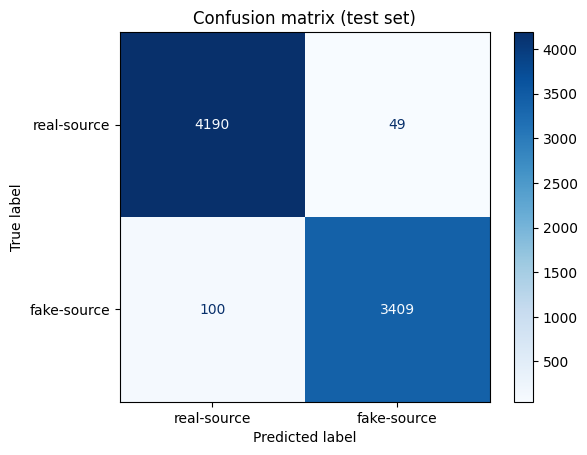

{'n_train': 30991, 'n_test': 7748, 'real': {'precision': 0.9766899766899767, 'recall': 0.9884406699693324, 'f1': 0.9825301911126744}, 'fake': {'precision': 0.9858299595141701, 'recall': 0.9715018523795953, 'f1': 0.9786134634706474}, 'confusion_matrix': [[4190, 49], [100, 3409]]}


In [18]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["real-source (0)", "fake-source (1)"], digits=4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real-source", "fake-source"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.show()

p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average=None, labels=[0, 1])
METRICS = {
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "real": {"precision": float(p[0]), "recall": float(r[0]), "f1": float(f1[0])},
    "fake": {"precision": float(p[1]), "recall": float(r[1]), "f1": float(f1[1])},
    "confusion_matrix": cm.tolist(),
}
print(METRICS)

In [19]:
vec = model.named_steps["tfidf"]; clf = model.named_steps["clf"]
names = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]
order = np.argsort(coef)
print("Top 25 features pushing towards REAL-source:")
print(", ".join(names[order[:25]]))
print("\nTop 25 features pushing towards FAKE-source:")
print(", ".join(names[order[-25:][::-1]]))

Top 25 features pushing towards REAL-source:
said, president donald, wednesday, tuesday, thursday, friday, republican, nov, monday, said statement, minister, president barack, spokesman, democratic, presidential, told, trump said, comment, reporters, said thursday, percent, house representatives, representatives, britain, said wednesday

Top 25 features pushing towards FAKE-source:
video, just, gop, read, watch, president trump, obama, america, like, president obama, hillary, breaking, mr, fact, rep, didn, isn, doesn, sen, american, actually, isis, know, really, trump


In [20]:
errors = pd.DataFrame({"text": X_test.values, "true": y_test.values, "pred": y_pred})
errors = errors[errors["true"] != errors["pred"]]
print("Total errors:", len(errors), "| false 'fake' on real-source:", ((errors.true==0)&(errors.pred==1)).sum(),
      "| missed fake-source:", ((errors.true==1)&(errors.pred==0)).sum())
for _, row in errors.sample(min(8, len(errors)), random_state=SEED).iterrows():
    print(f"\n[true={row.true} pred={row.pred}] {row.text[:300]}...")

Total errors: 149 | false 'fake' on real-source: 49 | missed fake-source: 100

[true=1 pred=0] Chris Christie Reportedly Told Trump To Take His Cabinet Positions And Shove ‘Em. Sources say that Chris Christie was offered several positions in Donald Trump s administration but turned them all down.On Sunday, reported: The sources said those jobs included Cabinet-level posts like Homeland Securi...

[true=1 pred=0] DESPERATION OR STUPIDITY? GERMAN State Recruits REFUGEES With No Passports For Police Officer Jobs. It s too late for these countries who ve been invaded by mostly young Muslim male refugees to turn back the clock. Bavaria is now being forced to do whatever they can to fight back against terrorism i...

[true=1 pred=0] BREAKING: IRAN THROWS DOWN ULTIMATUM: …Your Move Barry. The nuclear industry is a necessity, for energy production, for desalination, and in the fields of medicine, agriculture and other sectors. -Iran s Supreme Leader Ayatollah Ali KhameneiSo many lies Is it fin

In [21]:
joblib.dump(model, "model.joblib")
with open("model_metrics.json", "w") as f:
    json.dump({"versions": VERSIONS, "metrics": METRICS}, f, indent=2)

reloaded = joblib.load("model.joblib")
assert (reloaded.predict(X_test[:500]) == model.predict(X_test[:500])).all()
print("reload test passed")

def predict_text(text, model=reloaded):
    """Return a cautious risk indicator for one article. Not a verdict on truth."""
    if not text or len(text.strip()) < 100:
        return {"status": "insufficient_text",
                "message": "Not enough text to analyse."}
    cleaned = clean_text(text)
    p_fake_style = float(model.predict_proba([cleaned])[0][1])
    if p_fake_style >= 0.8:
        band = "high_similarity_to_fake_source_style"
    elif p_fake_style <= 0.2:
        band = "low_similarity_to_fake_source_style"
    else:
        band = "uncertain"
    return {
        "status": "ok",
        "fake_source_style_score": round(p_fake_style, 4),
        "band": band,
        "disclaimer": "Statistical pattern match with the training data; not proof that the article is true or false.",
    }

print(predict_text(X_test.iloc[0]))
print(predict_text("too short"))

reload test passed
{'status': 'ok', 'fake_source_style_score': 0.9825, 'band': 'high_similarity_to_fake_source_style', 'disclaimer': 'Statistical pattern match with the training data; not proof that the article is true or false.'}
{'status': 'insufficient_text', 'message': 'Not enough text to analyse.'}


In [23]:
from google.colab import files
files.download("model.joblib")
files.download("model_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>